# Notebook 3: Text Generation and Its Evaluation Metrics

**What you will do:** train a language model from scratch (an interpolated trigram model), generate text with different **decoding strategies**, and evaluate it with the metrics from the presentation: **perplexity**, **BLEU**, **distinct-n / self-BLEU / repetition**, a **MAUVE-style distribution comparison**, a **FActScore-style fact check**, and **Elo / Bradley-Terry ranking with simulated LLM judges** (position and length bias). On Colab the same suite also runs on **GPT-2**.

| Part | Content | Needs internet / GPU? |
|---|---|---|
| 1 | Data: 1,300 real English sentences (Python documentation, built into Python) | no |
| 2 | Perplexity: from scratch, toy check, learning curve, tokenizer caveat | no |
| 3 | An n-gram language model and decoding strategies (greedy, temperature, top-k, top-p) | no |
| 4 | Diversity and repetition: distinct-n, self-BLEU, repetition rate | no |
| 5 | BLEU from scratch, and why it is a weak proxy for open-ended generation | no |
| 6 | MAUVE-style score from scratch (TF-IDF features) | no |
| 7 | Real LM: GPT-2 with the same metrics (and the real MAUVE) | optional (Colab) |
| 8 | FActScore-style evaluation with atomic facts | no |
| 9 | Pairwise comparison: Elo, Bradley-Terry, judge biases, length control (simulation) | no |

**Safe by design:** model cells are wrapped in `try/except` and skip gracefully when GPT-2 cannot be loaded, so **Run all** always works. Set `USE_MODELS = False` to skip neural models on purpose.

In [1]:
# Colab only: libraries (torch and transformers are preinstalled). mauve-text is optional (Part 7).
!pip -q install sacrebleu mauve-text

In [2]:
import re, math, random, collections
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sacrebleu
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression

pd.set_option("display.precision", 3)
pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 110)
random.seed(0); np.random.seed(0)
USE_MODELS = True   # set False to skip all neural models
print("Setup OK")

Setup OK


## Part 1: Data

We need real human-written text without downloading anything. Python ships its own documentation as text (`pydoc_data.topics`). We keep clean prose sentences (no code, no markup). The text is technical, but it is genuine English written by people, which is all we need to **train a language model and to have a human reference distribution**.

All text is lowercased and stripped of punctuation for the n-gram model (the neural model on Colab uses the raw sentences).

In [3]:
from pydoc_data import topics

def load_sentences():
    text = "\n\n".join(topics.topics.values())
    sents = []
    for p in re.split(r"\n\s*\n", text):
        if ">>>" in p or "::" in p or "|" in p or p.lstrip().startswith(("*", "-", "+", "..", "$", "def ", "class ")):
            continue
        p = " ".join(p.replace("`", "").replace("*", "").replace("’", "'").split())
        if len(p) < 50:
            continue
        for s in re.split(r"(?<=[.!?])\s+(?=[A-Z])", p):
            w = s.split()
            if not (6 <= len(w) <= 30) or not s.isascii() or s[-1] not in ".!?":
                continue
            alpha = sum(ch.isalpha() or ch == " " for ch in s) / len(s)
            if alpha >= 0.9 and not re.search(r"[A-Za-z]_|\(\)|=|\[|\]|\{|\}|\bhttp|<|>", s):
                sents.append(s)
    return list(dict.fromkeys(sents))

RAW = load_sentences()
rng0 = random.Random(0)
rng0.shuffle(RAW)
assert len(RAW) > 500, "unexpectedly small corpus"

def norm_tokens(s):
    return re.findall(r"[a-z0-9']+", s.lower())

n = len(RAW)
cut1, cut2 = int(0.70 * n), int(0.80 * n)
TRAIN_RAW, VALID_RAW, TEST_RAW = RAW[:cut1], RAW[cut1:cut2], RAW[cut2:]
TRAIN, VALID, TEST = [norm_tokens(s) for s in TRAIN_RAW], [norm_tokens(s) for s in VALID_RAW], [norm_tokens(s) for s in TEST_RAW]
print(f"{n} sentences -> train {len(TRAIN)}, validation {len(VALID)}, test {len(TEST)}")
print("words in train:", sum(map(len, TRAIN)))
print("Example:", TRAIN_RAW[0])

1301 sentences -> train 910, validation 130, test 261
words in train: 14190
Example: It can also be used to escape characters that otherwise have a special meaning, such as newline, backslash itself, or the quote character.


## Part 2: Perplexity

**Perplexity** measures how *surprised* a language model is by real text:

$$\text{PPL} = \exp\Big(-\frac1N\sum_{t=1}^{N}\ln p(w_t\mid w_{<t})\Big)$$

It is the exponential of the average negative log-probability. A perplexity of 10 means the model is as unsure as if it picked among **10 equally likely words** at every step. Lower is better.

First the toy numbers from slide 9, then a real model.

In [4]:
def ppl_from_probs(ps):
    return math.exp(-sum(math.log(p) for p in ps) / len(ps))

A_probs = [0.5, 0.4, 0.6, 0.5]
B_probs = [0.1, 0.05, 0.2, 0.1]
print(f"Model A: PPL = {ppl_from_probs(A_probs):.2f}")
print(f"Model B: PPL = {ppl_from_probs(B_probs):.2f}")
print(f"Uniform over 50,000 words: PPL = {ppl_from_probs([1/50000]*5):,.0f}   (a model that guesses has PPL equal to the vocabulary size)")
assert abs(ppl_from_probs(A_probs) - 2.0205) < 1e-3 and abs(ppl_from_probs(B_probs) - 10.0) < 1e-9
assert abs(ppl_from_probs([1/50000]*5) - 50000) < 1e-6
print("Matches slide 9: PPL 2.0 and 10.0")

Model A: PPL = 2.02
Model B: PPL = 10.00
Uniform over 50,000 words: PPL = 50,000   (a model that guesses has PPL equal to the vocabulary size)
Matches slide 9: PPL 2.0 and 10.0


### An interpolated trigram language model

The next-word probability mixes three estimates:

$$p(w\mid u,v)=\lambda_3\,\hat p(w\mid u,v)+\lambda_2\,\hat p(w\mid v)+\lambda_1\,\hat p(w)$$

* trigram, bigram and unigram relative frequencies, with an add-one unigram so that every word has some probability
* words seen fewer than 2 times become `<unk>`
* the weights λ are chosen on the **validation** set (never on the test set)

In [5]:
class NGramLM:
    def __init__(self, train, min_count=2, lams=(0.1, 0.3, 0.6), vocab_words=None):
        counts = Counter(w for s in train for w in s)
        words = vocab_words if vocab_words is not None else [w for w, c in counts.items() if c >= min_count]
        self.vocab = ["<unk>", "<s>", "</s>"] + sorted(words)
        self.idx = {w: i for i, w in enumerate(self.vocab)}
        V = len(self.vocab)
        uni = np.zeros(V)
        self.bi, self.tri = defaultdict(Counter), defaultdict(Counter)
        for s in train:
            ids = [1, 1] + [self.idx.get(w, 0) for w in s] + [2]
            for k in range(2, len(ids)):
                uni[ids[k]] += 1
                self.bi[ids[k - 1]][ids[k]] += 1
                self.tri[(ids[k - 2], ids[k - 1])][ids[k]] += 1
        p1 = uni + 1.0
        p1[1] = 0.0                                   # <s> is never predicted
        self.p1 = p1 / p1.sum()
        self.bi_tot = {c: sum(d.values()) for c, d in self.bi.items()}
        self.tri_tot = {c: sum(d.values()) for c, d in self.tri.items()}
        self.lams = lams

    def ids(self, words):
        return [self.idx.get(w, 0) for w in words]

    def probs(self, u, v):
        # dense next-word distribution given the previous two word ids (u, v)
        l1, l2, l3 = self.lams
        has_tri, has_bi = (u, v) in self.tri, v in self.bi
        w3 = l3 if has_tri else 0.0
        w2 = (l2 + (l3 - w3)) if has_bi else 0.0
        w1 = 1.0 - w2 - w3
        p = w1 * self.p1
        if has_bi:
            for w, c in self.bi[v].items():
                p[w] += w2 * c / self.bi_tot[v]
        if has_tri:
            for w, c in self.tri[(u, v)].items():
                p[w] += w3 * c / self.tri_tot[(u, v)]
        return p

    def nll(self, sents):
        # returns (total negative log-likelihood, number of predicted tokens) incl. the end-of-sentence token
        tot, cnt = 0.0, 0
        for s in sents:
            ids = [1, 1] + self.ids(s) + [2]
            for k in range(2, len(ids)):
                tot -= math.log(self.probs(ids[k - 2], ids[k - 1])[ids[k]])
                cnt += 1
        return tot, cnt

    def perplexity(self, sents):
        tot, cnt = self.nll(sents)
        return math.exp(tot / cnt)

lm = NGramLM(TRAIN)
print("vocabulary size:", len(lm.vocab))
print("validation perplexity (default weights):", round(lm.perplexity(VALID), 1))

vocabulary size: 1066
validation perplexity (default weights): 111.5


In [6]:
# Choose the interpolation weights on the VALIDATION set
rows = []
for l3 in [0.0, 0.2, 0.4, 0.6, 0.8]:
    for l2 in [0.0, 0.2, 0.4, 0.6, 0.8]:
        l1 = 1 - l2 - l3
        if l1 < 0.04:
            continue
        m = NGramLM(TRAIN, lams=(l1, l2, l3))
        rows.append((round(l1, 2), round(l2, 2), round(l3, 2), m.perplexity(VALID)))
grid = pd.DataFrame(rows, columns=["lambda1 (unigram)", "lambda2 (bigram)", "lambda3 (trigram)", "valid PPL"]).sort_values("valid PPL")
display(grid.head(5))
BEST = tuple(grid.iloc[0][["lambda1 (unigram)", "lambda2 (bigram)", "lambda3 (trigram)"]].astype(float))
lm = NGramLM(TRAIN, lams=BEST)

compare = {"unigram only": (1.0, 0.0, 0.0), "bigram-ish": (0.2, 0.8, 0.0), "tuned interpolation": BEST}
res = {name: NGramLM(TRAIN, lams=l).perplexity(TEST) for name, l in compare.items()}
display(pd.Series(res, name="TEST perplexity").to_frame())
print("Higher-order context lowers perplexity: the model is less surprised by real text.")

,lambda1 (unigram),lambda2 (bigram),lambda3 (trigram),valid PPL
7,0.4,0.4,0.2,81.633
10,0.4,0.2,0.4,84.302
6,0.6,0.2,0.2,84.856
3,0.4,0.6,0.0,89.235
8,0.2,0.6,0.2,89.510


,TEST perplexity
unigram only,211.895
bigram-ish,96.153
tuned interpolation,78.704


Higher-order context lowers perplexity: the model is less surprised by real text.


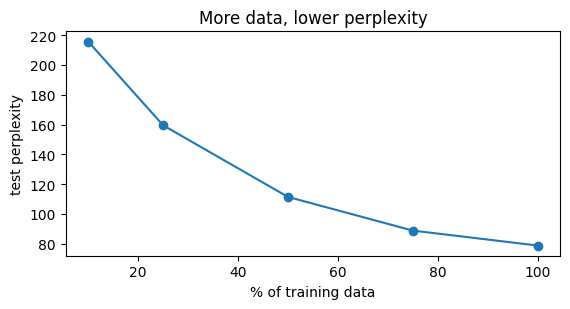

[215.7, 159.5, 111.4, 88.7, 78.7]
The vocabulary is held fixed. If it grew with the data, perplexities would not be comparable: a tiny vocabulary turns most
words into <unk>, which is easy to predict (a tokenizer/vocabulary effect, like the per-word vs per-character caveat below).


In [7]:
# Learning curve: more training text -> lower perplexity
fr = [0.1, 0.25, 0.5, 0.75, 1.0]
FIXED_VOCAB = [w for w in lm.vocab[3:]]          # same vocabulary for every size, so the numbers are comparable
curve = [NGramLM(TRAIN[:max(5, int(f * len(TRAIN)))], lams=BEST, vocab_words=FIXED_VOCAB).perplexity(TEST) for f in fr]
plt.figure(figsize=(5.8, 3.2))
plt.plot([f * 100 for f in fr], curve, "o-")
plt.xlabel("% of training data"); plt.ylabel("test perplexity"); plt.title("More data, lower perplexity"); plt.tight_layout(); plt.show()
print([round(c, 1) for c in curve])
print("The vocabulary is held fixed. If it grew with the data, perplexities would not be comparable: a tiny vocabulary turns most")
print("words into <unk>, which is easy to predict (a tokenizer/vocabulary effect, like the per-word vs per-character caveat below).")

### Perplexity is not comparable across tokenizers

A perplexity is an average **per token**. If one model uses words and another uses characters (or sub-words), their numbers mean different things. The same total log-likelihood gives very different perplexities depending on what you divide by:

In [8]:
tot, n_words = lm.nll(TEST)
n_chars = sum(len(" ".join(s)) + 1 for s in TEST)
print(f"total negative log-likelihood of the test set: {tot:,.0f} nats")
print(f"per WORD      : perplexity = {math.exp(tot / n_words):10.1f}   ({n_words:,} words)")
print(f"per CHARACTER : perplexity = {math.exp(tot / n_chars):10.2f}   ({n_chars:,} characters)")
print("\nSame model, same text, same total probability. Only the unit changed. Always compare models at the same unit")
print("(for example per word), as we do later when we compare the n-gram model with GPT-2.")

total negative log-likelihood of the test set: 18,161 nats
per WORD      : perplexity =       78.7   (4,160 words)
per CHARACTER : perplexity =       2.19   (23,179 characters)

Same model, same text, same total probability. Only the unit changed. Always compare models at the same unit
(for example per word), as we do later when we compare the n-gram model with GPT-2.


## Part 3: Generating text and decoding strategies

A language model gives a distribution over the next word; **decoding** decides how to pick from it:

| Strategy | Rule | Typical effect |
|---|---|---|
| **greedy** | always the most likely word | safe but repetitive |
| **temperature T** | sample from p^(1/T) | T < 1 safer, T > 1 more random |
| **top-k** | sample among the k most likely | cuts the unlikely tail |
| **top-p (nucleus)** | sample among the smallest set with probability mass >= p | adaptive tail cut |

In [9]:
def decode_next(p, mode="sample", temperature=1.0, top_k=None, top_p=None, rng=None):
    p = p.copy()
    p[0] = 0.0; p[1] = 0.0                                  # never emit <unk> or <s>
    if mode == "greedy":
        return int(np.argmax(p))
    q = np.power(p / p.sum(), 1.0 / temperature)             # temperature
    q /= q.sum()
    if top_k:
        keep = np.argsort(-q)[:top_k]
        mask = np.zeros_like(q); mask[keep] = 1; q = q * mask; q /= q.sum()
    if top_p:
        order = np.argsort(-q)
        cum = np.cumsum(q[order])
        cutoff = int(np.searchsorted(cum, top_p) + 1)
        mask = np.zeros_like(q); mask[order[:cutoff]] = 1; q = q * mask; q /= q.sum()
    return int(rng.choice(len(q), p=q))

def generate_ngram(model, prompt_words, max_len=25, seed=0, **decode):
    rng = np.random.default_rng(seed)
    ids = [1, 1] + model.ids(prompt_words)
    out = list(prompt_words)
    while len(out) < max_len:
        nxt = decode_next(model.probs(ids[-2], ids[-1]), rng=rng, **decode)
        if nxt == 2:
            break
        ids.append(nxt); out.append(model.vocab[nxt])
    return " ".join(out)

SETTINGS = {"greedy": dict(mode="greedy"),
            "T=0.7": dict(mode="sample", temperature=0.7),
            "pure sampling (T=1)": dict(mode="sample", temperature=1.0),
            "top-k (k=10)": dict(mode="sample", top_k=10),
            "top-p (p=0.9)": dict(mode="sample", top_p=0.9),
            "T=1.5": dict(mode="sample", temperature=1.5)}

PROMPTS = [s[:2] for s in TEST]            # the first two words of every test sentence
for name, kw in SETTINGS.items():
    print(f"{name:20s} ->", generate_ngram(lm, PROMPTS[0], seed=1, **kw))
print("\nHuman sentence:", " ".join(TEST[0]))

greedy               -> if the string is a the the the the the the the the the the the the the the the the the the the the
T=0.7                -> if the of the case the instance is the if the
pure sampling (T=1)  -> if the modules which brackets the fails
top-k (k=10)         -> if the same value
top-p (p=0.9)        -> if the name variable annotations the field evaluated when means specified
T=1.5                -> if the loop without argument unlike false index style leaves one a section jump forward the executable in attempting is code copied they command is

Human sentence: if the or pattern fails the as pattern fails


In [10]:
GEN = {name: [generate_ngram(lm, pr, seed=i, **kw) for i, pr in enumerate(PROMPTS)] for name, kw in SETTINGS.items()}
HUMAN = [" ".join(s[:25]) for s in TEST]        # human reference texts, truncated to the same maximum length
print({k: len(v) for k, v in GEN.items()}, "| human texts:", len(HUMAN))

{'greedy': 261, 'T=0.7': 261, 'pure sampling (T=1)': 261, 'top-k (k=10)': 261, 'top-p (p=0.9)': 261, 'T=1.5': 261} | human texts: 261


## Part 4: Diversity and repetition

Perplexity says nothing about **repetition**, a classic failure of generation. Three simple metrics:

* **distinct-n** = unique n-grams / all n-grams (over the whole set of outputs). Low means repetitive.
* **self-BLEU** = BLEU of each output against the **other outputs**. High means the outputs look alike (low diversity).
* **repetition rate** = share of n-grams inside one text that already appeared earlier in that same text.

In [11]:
def ngrams(tokens, n):
    return [tuple(tokens[i:i + n]) for i in range(len(tokens) - n + 1)]

def distinct_n(texts, n):
    g = [x for t in texts for x in ngrams(t.split(), n)]
    return len(set(g)) / len(g) if g else 0.0

def repetition_rate(text, n=3):
    g = ngrams(text.split(), n)
    return 1 - len(set(g)) / len(g) if g else 0.0

def self_bleu(texts, sample=40, seed=0):
    idx = random.Random(seed).sample(range(len(texts)), min(sample, len(texts)))
    scores = [sacrebleu.sentence_bleu(texts[i], [t for j, t in enumerate(texts) if j != i]).score for i in idx]
    return float(np.mean(scores))

# toy check from slide 9
rep, div = "the the the the the the the the", "the quick brown fox jumps over the lazy dog"
print("distinct-1:", distinct_n([rep], 1), "(repeated)   vs", round(distinct_n([div], 1), 3), "(varied)")
assert distinct_n([rep], 1) == 0.125 and abs(distinct_n([div], 1) - 8 / 9) < 1e-9
print("Matches slide 9: 0.125 versus 0.89")

distinct-1: 0.125 (repeated)   vs 0.889 (varied)
Matches slide 9: 0.125 versus 0.89


In [12]:
def basic_report(texts, model):
    ppl_self = model.perplexity([t.split() for t in texts])
    return dict(avg_len=np.mean([len(t.split()) for t in texts]), distinct1=distinct_n(texts, 1), distinct2=distinct_n(texts, 2),
                self_BLEU=self_bleu(texts), repetition3=np.mean([repetition_rate(t) for t in texts]), PPL_of_output=ppl_self)

rep_rows = {name: basic_report(texts, lm) for name, texts in GEN.items()}
rep_rows["human (test)"] = basic_report(HUMAN, lm)
report = pd.DataFrame(rep_rows).T
display(report)
print("Greedy and top-k get a LOW perplexity under the model (it loves its own favourite words) but greedy is repetitive: distinct-2 0.13, 35% repeated trigrams.")
print("T=1.5 : very diverse but the model assigns it a huge perplexity: the text is noise.")
print("Lesson: low perplexity of the OUTPUT does not mean good text. Real text sits in between.")

,avg_len,distinct1,distinct2,self_BLEU,repetition3,PPL_of_output
greedy,15.713,0.075,0.134,83.799,3.545e-01,27.318
T=0.7,11.199,0.211,0.638,33.317,3.332e-04,25.381
pure sampling (T=1),13.475,0.220,0.808,18.316,0.000e+00,80.679
top-k (k=10),9.092,0.193,0.535,44.701,6.140e-04,22.425
top-p (p=0.9),12.556,0.197,0.762,23.545,0.000e+00,55.392
T=1.5,17.877,0.209,0.949,11.254,0.000e+00,495.885
human (test),14.743,0.245,0.762,18.516,1.993e-03,78.258


Greedy and top-k get a LOW perplexity under the model (it loves its own favourite words) but greedy is repetitive: distinct-2 0.13, 35% repeated trigrams.
T=1.5 : very diverse but the model assigns it a huge perplexity: the text is noise.
Lesson: low perplexity of the OUTPUT does not mean good text. Real text sits in between.


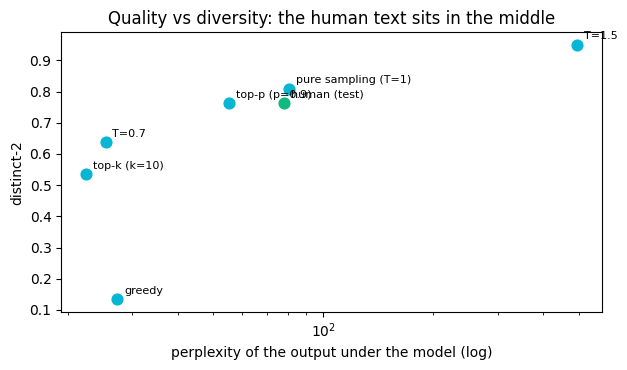

In [13]:
plt.figure(figsize=(6.4, 3.8))
for name, row in report.iterrows():
    plt.scatter(row["PPL_of_output"], row["distinct2"], s=60, color="#10b981" if "human" in name else "#06b6d4")
    plt.annotate(name, (row["PPL_of_output"], row["distinct2"]), textcoords="offset points", xytext=(5, 4), fontsize=8)
plt.xscale("log"); plt.xlabel("perplexity of the output under the model (log)"); plt.ylabel("distinct-2")
plt.title("Quality vs diversity: the human text sits in the middle"); plt.tight_layout(); plt.show()

## Part 5: BLEU, and why it is a weak proxy for open-ended generation

**BLEU** (**B**i**L**ingual **E**valuation **U**nderstudy, Papineni et al., 2002) was made for machine translation:

$$\text{BLEU}=\text{BP}\cdot\exp\Big(\sum_{n=1}^{4} w_n \ln p_n\Big),\qquad \text{BP}=\min\big(1,\ e^{1-r/c}\big)$$

* $p_n$ = **clipped** n-gram precision (a word cannot be counted more often than in the reference)
* BP = **brevity penalty** (r = reference length, c = candidate length), so very short outputs cannot score well
* $w_n = 1/4$; when some $p_n$ is zero we use the same *exponential smoothing* as sacreBLEU

In [14]:
def bleu_scratch(hyp, ref, max_n=4):
    h, r = hyp.lower().split(), ref.lower().split()
    log_sum, smooth = 0.0, 1.0
    p_list = []
    for n in range(1, max_n + 1):
        hc, rc = Counter(ngrams(h, n)), Counter(ngrams(r, n))
        match, total = sum((hc & rc).values()), max(sum(hc.values()), 1)
        if match == 0:
            smooth *= 2
            p = 1 / (smooth * total)               # exponential smoothing (as in sacreBLEU)
        else:
            p = match / total
        p_list.append((match, total, p))
        log_sum += math.log(p) / max_n
    bp = 1.0 if len(h) >= len(r) else math.exp(1 - len(r) / len(h))
    return 100 * bp * math.exp(log_sum), bp, p_list

ref = "the cat is sitting on the mat"
hyp = "the cat sat on the mat"
mine, bp, plist = bleu_scratch(hyp, ref)
lib = sacrebleu.sentence_bleu(hyp, [ref]).score
print("clipped matches:", [(m, t) for m, t, _ in plist], " BP =", round(bp, 3))
print(f"BLEU from scratch = {mine:.2f}    sacreBLEU = {lib:.2f}")
assert abs(mine - lib) < 0.15 and abs(plist[0][2] - 5 / 6) < 1e-9 and abs(plist[1][2] - 3 / 5) < 1e-9 and abs(bp - 0.846) < 1e-3
print("Matches slide 9: p1 = 5/6, p2 = 3/5, BP = 0.85, BLEU = 32.2")

clipped matches: [(5, 6), (3, 5), (1, 4), (0, 3)]  BP = 0.846
BLEU from scratch = 32.16    sacreBLEU = 32.16
Matches slide 9: p1 = 5/6, p2 = 3/5, BP = 0.85, BLEU = 32.2


In [15]:
# BLEU of generated sentences against the ONE true sentence that started with the same two words.
# In open-ended generation many continuations are fine, but BLEU only rewards copying THE reference.
bleu_rows = {}
for name, texts in GEN.items():
    refs = [" ".join(s[:25]) for s in TEST]
    bleu_rows[name] = sacrebleu.corpus_bleu(texts, [refs]).score
bleu_df = pd.Series(bleu_rows, name="corpus BLEU vs the human sentence").to_frame()
display(bleu_df)
print("All scores are tiny (the continuation almost never equals the one reference sentence), even for the more")
print("sensible decodings. BLEU suits translation (one correct answer), not open-ended text generation.")

,corpus BLEU vs the human sentence
greedy,4.988
T=0.7,3.180
pure sampling (T=1),1.265
top-k (k=10),2.434
top-p (p=0.9),1.358
T=1.5,0.551


All scores are tiny (the continuation almost never equals the one reference sentence), even for the more
sensible decodings. BLEU suits translation (one correct answer), not open-ended text generation.


## Part 6: MAUVE-style comparison of distributions

**MAUVE** (Pillutla et al., NeurIPS 2021) does not compare single sentences. It compares the **distribution of model text** $Q$ with the **distribution of human text** $P$:

1. embed human and model texts (the real MAUVE uses GPT-2 features; here **TF-IDF + SVD**, so it runs offline)
2. **quantize** the embeddings with k-means so each set becomes a histogram over clusters
3. build mixtures $R_\lambda=\lambda P+(1-\lambda)Q$ and trace the **divergence frontier** $\big(e^{-c\,KL(Q\|R_\lambda)},\ e^{-c\,KL(P\|R_\lambda)}\big)$
4. **MAUVE = area under the curve**, between 0 and 1 (1 = same distribution)

The two axes are the two errors: model text humans would never write (Q has mass where P has none) and human text the model never produces.

In [16]:
def kl(p, q):
    mask = p > 0
    return float(np.sum(p[mask] * np.log(p[mask] / q[mask])))

def mauve_lite(p_texts, q_texts, k=None, c=5.0, n_lambdas=50, dim=40, seed=0):
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
    X = vec.fit_transform(p_texts + q_texts)
    Z = TruncatedSVD(n_components=min(dim, X.shape[1] - 1), random_state=seed).fit_transform(X)
    Z /= (np.linalg.norm(Z, axis=1, keepdims=True) + 1e-12)
    k = k or max(2, len(Z) // 10)
    labels = KMeans(n_clusters=k, n_init=5, random_state=seed).fit_predict(Z)
    P = np.bincount(labels[:len(p_texts)], minlength=k) / len(p_texts)
    Q = np.bincount(labels[len(p_texts):], minlength=k) / len(q_texts)
    xs, ys = [0.0], [1.0]
    for lam in np.linspace(1e-3, 1 - 1e-3, n_lambdas):
        R = lam * P + (1 - lam) * Q
        xs.append(math.exp(-c * kl(Q, R))); ys.append(math.exp(-c * kl(P, R)))
    xs.append(1.0); ys.append(0.0)
    order = np.argsort(xs)
    x, y = np.array(xs)[order], np.array(ys)[order]
    area = float(np.sum((x[1:] - x[:-1]) * (y[1:] + y[:-1]) / 2))     # trapezoid rule
    return area, (x, y)

# sanity checks
half = len(HUMAN) // 2
same_dist, _ = mauve_lite(HUMAN[:half], HUMAN[half:])
shuffled = [" ".join(random.Random(i).sample(t.split(), len(t.split()))) for i, t in enumerate(HUMAN)]
repeated = ["the " * 20 for _ in HUMAN]
print(f"human vs human (two halves of the test set): {same_dist:.3f}   (should be close to 1)")
print(f"human vs word-shuffled human text          : {mauve_lite(HUMAN, shuffled)[0]:.3f}   <- NOT detected: TF-IDF only sees which words occur, not their order")
print(f"human vs 'the the the ...'                 : {mauve_lite(HUMAN, repeated)[0]:.3f}   (should be near 0)")

human vs human (two halves of the test set): 0.870   (should be close to 1)
human vs word-shuffled human text          : 1.000   <- NOT detected: TF-IDF only sees which words occur, not their order
human vs 'the the the ...'                 : 0.004   (should be near 0)


,MAUVE-lite vs human
T=0.7,0.871
top-p (p=0.9),0.831
T=1.5,0.823
pure sampling (T=1),0.746
top-k (k=10),0.620
greedy,0.128


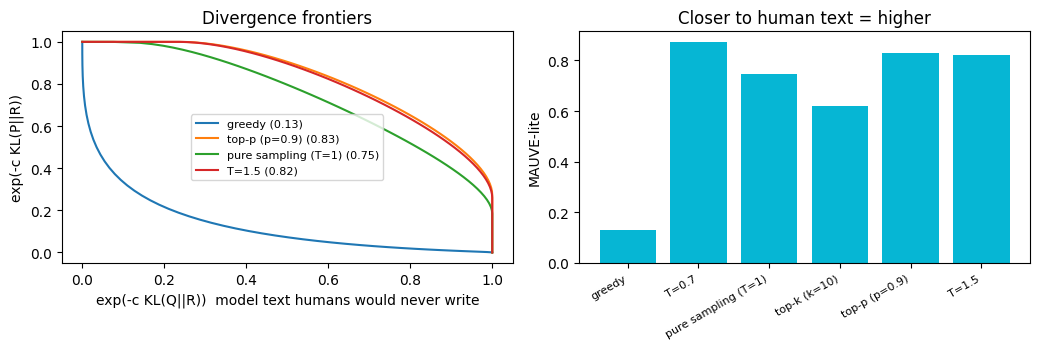

In [17]:
mauve_rows, curves = {}, {}
for name, texts in GEN.items():
    m, curve = mauve_lite(HUMAN, texts)
    mauve_rows[name] = m; curves[name] = curve
mauve_df = pd.Series(mauve_rows, name="MAUVE-lite vs human").to_frame()
display(mauve_df.sort_values("MAUVE-lite vs human", ascending=False))

fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.6))
for name in ["greedy", "top-p (p=0.9)", "pure sampling (T=1)", "T=1.5"]:
    ax[0].plot(*curves[name], label=f"{name} ({mauve_rows[name]:.2f})")
ax[0].set_xlabel("exp(-c KL(Q||R))  model text humans would never write"); ax[0].set_ylabel("exp(-c KL(P||R))")
ax[0].set_title("Divergence frontiers"); ax[0].legend(fontsize=8)
ax[1].bar(range(len(mauve_df)), mauve_df.iloc[:, 0], color="#06b6d4"); ax[1].set_xticks(range(len(mauve_df)))
ax[1].set_xticklabels(mauve_df.index, rotation=30, ha="right", fontsize=8); ax[1].set_ylabel("MAUVE-lite"); ax[1].set_title("Closer to human text = higher")
plt.tight_layout(); plt.show()

**Reading the result.** Greedy decoding is clearly far from the human distribution (about 0.13): its outputs collapse into a few clusters. Moderate sampling (T = 0.7, top-p) is closest. *Honest limitation:* our features are TF-IDF, a bag of words, so MAUVE-lite does **not** penalise T = 1.5 (word salad that still uses plausible words) and gives the word-shuffled text a perfect score. The real MAUVE uses GPT-2 embeddings (Part 7), which are sensitive to word order and fluency. That is exactly why the choice of embedding matters.

## Part 7: A real language model, GPT-2 (Colab)

We now run the **same metrics** on GPT-2 (124M parameters). The cell downloads the model (about 500 MB). If it cannot be loaded, the notebook prints a message and skips this part.

Two details that matter:

* **Perplexity per word.** GPT-2 predicts BPE sub-word tokens, so we divide the total negative log-likelihood by the number of **words** to compare it fairly with our word-level n-gram model.
* **Decoding.** `top_k=0` and `top_p=1.0` switch the filters off in Hugging Face.

In [18]:
GPT2 = None
if USE_MODELS:
    try:
        import torch
        from transformers import AutoTokenizer, AutoModelForCausalLM
        gdev = "cuda" if torch.cuda.is_available() else "cpu"
        g_tok = AutoTokenizer.from_pretrained("gpt2")
        g_model = AutoModelForCausalLM.from_pretrained("gpt2").to(gdev).eval()

        def gpt2_word_perplexity(sentences):
            tot_nll, tot_words = 0.0, 0
            for s in sentences:
                enc = g_tok(g_tok.bos_token + s, return_tensors="pt").to(gdev)
                with torch.no_grad():
                    loss = g_model(**enc, labels=enc["input_ids"]).loss      # mean NLL over predicted tokens
                tot_nll += loss.item() * (enc["input_ids"].shape[1] - 1)
                tot_words += len(s.split())
            return math.exp(tot_nll / tot_words)

        def gpt2_generate(prompt, max_new_tokens=25, seed=0, mode="sample", temperature=1.0, top_k=None, top_p=None):
            torch.manual_seed(seed)
            enc = g_tok(prompt, return_tensors="pt").to(gdev)
            kw = dict(max_new_tokens=max_new_tokens, pad_token_id=g_tok.eos_token_id)
            if mode == "greedy":
                kw["do_sample"] = False
            else:
                kw.update(do_sample=True, temperature=temperature, top_k=top_k or 0, top_p=top_p or 1.0)
            with torch.no_grad():
                out = g_model.generate(**enc, **kw)
            return g_tok.decode(out[0], skip_special_tokens=True)

        gpt2_generate("The function returns", max_new_tokens=5)       # smoke test
        GPT2 = True
        print("GPT-2 loaded on", gdev)
    except Exception as e:
        print(f"GPT-2 not available here ({type(e).__name__}); skipping the neural part of this notebook.")
else:
    print("USE_MODELS is False: skipping GPT-2.")

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

GPT-2 loaded on cpu


In [19]:
if GPT2:
    sample_test = TEST_RAW[:100]
    ppl_g = gpt2_word_perplexity(sample_test)
    ppl_n = lm.perplexity([norm_tokens(s) for s in sample_test])
    print(f"Word-level perplexity on the same 100 test sentences:  GPT-2 = {ppl_g:.1f}   n-gram = {ppl_n:.1f}")
    print("GPT-2 (never trained on this corpus) is much less surprised by real English than our tiny n-gram model.")
else:
    print("(skipped: GPT-2 not available)")

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Word-level perplexity on the same 100 test sentences:  GPT-2 = 229.6   n-gram = 82.7
GPT-2 (never trained on this corpus) is much less surprised by real English than our tiny n-gram model.


In [20]:
if GPT2:
    NEURAL_SETTINGS = {"greedy": dict(mode="greedy"), "T=0.7": dict(mode="sample", temperature=0.7),
                       "pure sampling (T=1)": dict(mode="sample", temperature=1.0),
                       "top-k (k=40)": dict(mode="sample", top_k=40), "top-p (p=0.9)": dict(mode="sample", top_p=0.9)}
    prompts_g = [" ".join(s.split()[:3]) for s in TEST_RAW[:100]]
    GEN_G = {}
    for name, kw in NEURAL_SETTINGS.items():
        GEN_G[name] = [norm_tokens(gpt2_generate(p, seed=i, **kw)) for i, p in enumerate(prompts_g)]
        GEN_G[name] = [" ".join(t[:25]) for t in GEN_G[name]]
    human_g = [" ".join(norm_tokens(s)[:25]) for s in TEST_RAW[:100]]
    rows = {}
    for name, texts in GEN_G.items():
        rows[name] = dict(distinct2=distinct_n(texts, 2), self_BLEU=self_bleu(texts), repetition3=np.mean([repetition_rate(t) for t in texts]),
                          MAUVE_lite=mauve_lite(human_g, texts, k=10)[0])
    display(pd.DataFrame(rows).T)
    print("Example (greedy):", GEN_G["greedy"][0])
    print("Example (top-p) :", GEN_G["top-p (p=0.9)"][0])
else:
    print("(skipped: GPT-2 not available)")

,distinct2,self_BLEU,repetition3,MAUVE_lite
greedy,0.555,33.708,0.109,0.496
T=0.7,0.808,10.725,0.012,0.995
pure sampling (T=1),0.928,6.829,0.007,0.997
top-k (k=40),0.863,9.762,0.005,0.970
top-p (p=0.9),0.916,7.760,0.003,0.901


Example (greedy): if the orc is not a member of the u s government it is not required to register as a foreign agent
Example (top-p) : if the orom button turns off the switch is enabled but it may not be disabled by default it does not have


In [21]:
# The REAL MAUVE (pip package mauve-text, GPT-2 features). Needs the downloaded model; optional.
if GPT2:
    try:
        import mauve
        out = mauve.compute_mauve(p_text=human_g, q_text=GEN_G["top-p (p=0.9)"], featurize_model_name="gpt2",
                                  max_text_length=64, device_id=0 if gdev == "cuda" else -1, verbose=False)
        print("Real MAUVE (human vs GPT-2 top-p):", round(out.mauve, 3))
        out2 = mauve.compute_mauve(p_text=human_g, q_text=GEN_G["greedy"], featurize_model_name="gpt2",
                                   max_text_length=64, device_id=0 if gdev == "cuda" else -1, verbose=False)
        print("Real MAUVE (human vs GPT-2 greedy):", round(out2.mauve, 3))
    except Exception as e:
        print(f"Real MAUVE not available here ({type(e).__name__}).")
else:
    print("(skipped: GPT-2 not available)")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Featurizing p:   0%|          | 0/100 [00:00<?, ?it/s]

Featurizing q:   0%|          | 0/100 [00:00<?, ?it/s]

Real MAUVE (human vs GPT-2 top-p): 0.327


Featurizing p:   0%|          | 0/100 [00:00<?, ?it/s]

Featurizing q:   0%|          | 0/100 [00:00<?, ?it/s]

Real MAUVE (human vs GPT-2 greedy): 0.386


## Part 8: FActScore-style evaluation with atomic facts

Fluent text can be **false**. **FActScore** (Min et al., EMNLP 2023) splits a long generation into **atomic facts** (one small claim each), checks every fact against a trusted knowledge source, and reports

$$\text{FActScore}=\frac{\#\text{supported atomic facts}}{\#\text{atomic facts}}$$

The real system decomposes the text with an LLM and retrieves evidence from Wikipedia. Here the knowledge source is a tiny dictionary and the atomic facts are written by hand, to show the **scoring logic**.

In [ ]:
# Knowledge source (fictional person)
KB = {("mara venn", "born in"): {"1970"},
      ("mara venn", "studied at"): {"harlow university"},
      ("mara venn", "lives in"): {"lisbon"},
      ("mara venn", "has children"): {"two"},
      ("mara venn", "wrote"): {"the glass orchard"}}

def factscore(facts, kb):
    verdicts = [obj in kb.get((subj, rel), set()) for subj, rel, obj in facts]
    return (sum(verdicts) / len(verdicts) if facts else 0.0), verdicts

# "Generated biography": Mara Venn was born in 1970, studied at Harlow University, won the Nobel Prize,
# lives in Lisbon and has three children.
bio_A = [("mara venn", "born in", "1970"), ("mara venn", "studied at", "harlow university"), ("mara venn", "won", "nobel prize"),
         ("mara venn", "lives in", "lisbon"), ("mara venn", "has children", "three")]
bio_B = [("mara venn", "born in", "1970"), ("mara venn", "wrote", "the glass orchard")]
score_A, v_A = factscore(bio_A, KB)
score_B, v_B = factscore(bio_B, KB)
display(pd.DataFrame({"atomic fact": [" ".join(f) for f in bio_A], "supported": v_A}))
print(f"FActScore(bio A) = {sum(v_A)}/{len(v_A)} = {score_A:.0%}      FActScore(bio B) = {sum(v_B)}/{len(v_B)} = {score_B:.0%}")
assert abs(score_A - 0.6) < 1e-9
print("Matches slide 10: 3 of 5 facts supported = 60%")
print("\nBio B is 'more factual' only because it says less. The real FActScore adds a length penalty for very short answers,")
print("and measures precision only: it does not reward covering many true facts (recall).")

## Part 9: Pairwise comparison, Elo, Bradley-Terry, and judge biases

For open-ended generation the most trusted evaluation is **preference**: show two answers, ask which is better (a human, or an **LLM judge**). **Chatbot Arena** turns many such votes into a ranking.

**Elo:** the probability that A beats B is

$$P(A\succ B)=\frac1{1+10^{-(R_A-R_B)/400}}$$

and ratings move after each game by $K\,(S-E)$. **Bradley-Terry** fits all ratings at once by maximum likelihood (the same model, without the order dependence of online Elo).

Everything below is a **simulation** (no real judge), made to show how the method and its biases behave.

In [23]:
def win_prob(ra, rb):
    return 1.0 / (1.0 + 10 ** ((rb - ra) / 400))

def elo_update(ra, rb, score_a, K=32):
    ea = win_prob(ra, rb)
    return ra + K * (score_a - ea), rb + K * ((1 - score_a) - (1 - ea))

print(f"1200 vs 1000: P(A wins) = {win_prob(1200, 1000):.3f}      equal ratings: {win_prob(1000, 1000):.2f}      1100 vs 1000: {win_prob(1100, 1000):.3f}")
ra, rb = elo_update(1000, 1000, 1.0)
print(f"After A beats B (both 1000, K=32): A = {ra:.0f}, B = {rb:.0f}")
assert abs(win_prob(1200, 1000) - 0.7597) < 1e-3 and (ra, rb) == (1016.0, 984.0)
print("Matches the guide: 1200 vs 1000 is a 76% win probability.")

1200 vs 1000: P(A wins) = 0.760      equal ratings: 0.50      1100 vs 1000: 0.640
After A beats B (both 1000, K=32): A = 1016, B = 984
Matches the guide: 1200 vs 1000 is a 76% win probability.


In [24]:
def simulate_votes(true_ratings, n_votes, seed=0):
    rng = np.random.default_rng(seed)
    m = len(true_ratings)
    votes = []
    for _ in range(n_votes):
        a, b = rng.choice(m, size=2, replace=False)
        a_wins = rng.random() < win_prob(true_ratings[a], true_ratings[b])
        votes.append((a, b, 1.0 if a_wins else 0.0))
    return votes

def wins_matrix(votes, m):
    W = np.zeros((m, m))
    for a, b, s in votes:
        if s == 1.0: W[a, b] += 1
        else: W[b, a] += 1
    return W

def bradley_terry(W, n_iter=300):
    m = W.shape[0]
    games = W + W.T
    p = np.ones(m)
    for _ in range(n_iter):                       # minorisation-maximisation updates
        for i in range(m):
            denom = sum(games[i, j] / (p[i] + p[j]) for j in range(m) if j != i)
            p[i] = max(W[i].sum(), 1e-9) / denom
        p /= np.exp(np.mean(np.log(p)))
    return 1000 + 400 * np.log10(p)               # back to the Elo scale (mean 1000)

def online_elo(votes, m, K=8, start=1000.0, seed=0):
    r = np.full(m, start)
    for a, b, s in votes:
        r[a], r[b] = elo_update(r[a], r[b], s, K)
    return r

NAMES = ["model A", "model B", "model C", "model D"]
TRUE = np.array([1150.0, 1050.0, 1000.0, 900.0])
votes = simulate_votes(TRUE, 3000, seed=1)
W = wins_matrix(votes, 4)
bt = bradley_terry(W)
el = online_elo(votes, 4)
out = pd.DataFrame({"true (centred)": TRUE - TRUE.mean() + 1000, "online Elo": el, "Bradley-Terry": bt}, index=NAMES)
display(out)
print("Bradley-Terry recovers the true ratings closely; online Elo is noisier because it depends on vote order.")
assert list(np.argsort(-bt)) == [0, 1, 2, 3]

,true (centred),online Elo,Bradley-Terry
model A,1125.0,1135.079,1117.612
model B,1025.0,1038.134,1022.843
model C,975.0,949.188,973.190
model D,875.0,877.599,886.355


Bradley-Terry recovers the true ratings closely; online Elo is noisier because it depends on vote order.


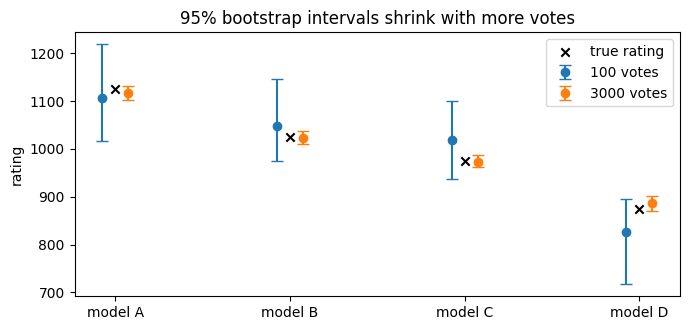

In [25]:
# How many votes do we need? Bootstrap intervals for 100 versus 3000 votes
def bt_ci(votes, m=4, B=200, seed=0):
    rng = np.random.default_rng(seed)
    runs = []
    for _ in range(B):
        idx = rng.integers(0, len(votes), len(votes))
        runs.append(bradley_terry(wins_matrix([votes[i] for i in idx], m), n_iter=100))
    runs = np.array(runs)
    return np.quantile(runs, 0.025, axis=0), np.quantile(runs, 0.975, axis=0)

fig, ax = plt.subplots(figsize=(7, 3.4))
for k, nv in enumerate([100, 3000]):
    v = votes[:nv]
    lo, hi = bt_ci(v)
    mid = bradley_terry(wins_matrix(v, 4))
    ax.errorbar(np.arange(4) + (k - 0.5) * 0.15, mid, yerr=[mid - lo, hi - mid], fmt="o", capsize=4, label=f"{nv} votes")
ax.scatter(np.arange(4), TRUE - TRUE.mean() + 1000, marker="x", color="black", zorder=5, label="true rating")
ax.set_xticks(range(4)); ax.set_xticklabels(NAMES); ax.set_ylabel("rating"); ax.legend(); ax.set_title("95% bootstrap intervals shrink with more votes")
plt.tight_layout(); plt.show()

### LLM-judge biases: position and length

LLM judges are not neutral. Zheng et al. (2023) found **position bias** (favouring the first answer), **verbosity bias** (favouring longer answers) and **self-preference**. We simulate a judge whose probability of picking A is

$$P(A)=\sigma\big(\beta_q(q_A-q_B)+\beta_\ell(\ell_A-\ell_B)+\beta_{pos}\big)$$

with true quality $q$, log-length $\ell$ and a bonus $\beta_{pos}$ for being shown first.

In [26]:
def sigmoid(x): return 1 / (1 + np.exp(-x))

rng = np.random.default_rng(0)
N = 20000
qA, qB = rng.normal(size=N), rng.normal(size=N)
lA, lB = rng.normal(0, 0.5, size=N), rng.normal(0, 0.5, size=N)         # log-lengths, independent of quality
b_q, b_len, b_pos = 2.0, 1.0, 0.6

def judge_prob_first_wins(q1, q2, l1, l2):
    return sigmoid(b_q * (q1 - q2) + b_len * (l1 - l2) + b_pos)

p_AB = judge_prob_first_wins(qA, qB, lA, lB)          # A shown first
p_BA = judge_prob_first_wins(qB, qA, lB, lA)          # B shown first
true_A_better = qA > qB
acc_single = np.mean((p_AB > 0.5) == true_A_better)                       # one judgement, A first
pA_swap_avg = 0.5 * (p_AB + (1 - p_BA))                                   # average over both orders
acc_swap = np.mean((pA_swap_avg > 0.5) == true_A_better)
consistent = np.mean((p_AB > 0.5) == (1 - p_BA > 0.5))
close = np.abs(qA - qB) < 0.1                                             # equal quality: who wins?
long_wins = np.mean(((p_AB > 0.5) == (lA > lB))[close] | False)
print(f"agreement with true quality, single order     : {acc_single:.3f}")
print(f"agreement with true quality, swap and average : {acc_swap:.3f}")
print(f"position consistency (same winner after swap)  : {consistent:.3f}   <- 1.0 would mean no position bias")
print(f"equal-quality pairs: the LONGER answer wins in {long_wins:.1%} of cases (50% = no length bias)")

agreement with true quality, single order     : 0.895
agreement with true quality, swap and average : 0.921
position consistency (same winner after swap)  : 0.838   <- 1.0 would mean no position bias
equal-quality pairs: the LONGER answer wins in 69.8% of cases (50% = no length bias)


In [27]:
# Length-controlled evaluation (idea of length-controlled AlpacaEval): fit a Bradley-Terry model WITH a length term.
# Three models: "good" (skill 0.6, normal length), "verbose" (skill 0.3, answers 2.2x longer), "bad" (skill 0.0, normal length).
skill = np.array([0.6, 0.3, 0.0]); loglen = np.array([0.0, math.log(2.2), 0.0]); M = ["good", "verbose", "bad"]
beta_len_judge = 1.2
rng = np.random.default_rng(3)
rows_X, y = [], []
for _ in range(6000):
    a, b = rng.choice(3, size=2, replace=False)
    la, lb = loglen[a] + rng.normal(0, 0.4), loglen[b] + rng.normal(0, 0.4)       # each answer has its own length
    logit = (skill[a] - skill[b]) + beta_len_judge * (la - lb)                      # a biased judge
    x = np.zeros(3); x[a] += 1; x[b] -= 1
    rows_X.append(np.append(x, la - lb))
    y.append(int(rng.random() < sigmoid(logit)))
Xd, y = np.array(rows_X), np.array(y)

def fit_strengths(X, y, use_len):
    cols = [0, 1, 2] + ([3] if use_len else [])
    clf = LogisticRegression(fit_intercept=False, C=1e4, max_iter=1000).fit(X[:, cols], y)
    s = clf.coef_[0][:3]
    return s - s.mean(), (clf.coef_[0][3] if use_len else np.nan)

raw, _ = fit_strengths(Xd, y, False)
lc, len_coef = fit_strengths(Xd, y, True)
true_c = skill - skill.mean()
tbl = pd.DataFrame({"true skill (centred)": true_c, "raw judge strength": raw, "length-controlled": lc}, index=M)
display(tbl)
print("Raw ranking :", " > ".join(np.array(M)[np.argsort(-raw)]), "   <- the verbose model wins just by writing more")
print("LC ranking  :", " > ".join(np.array(M)[np.argsort(-lc)]), "   <- matches the true skills")
print(f"estimated length coefficient: {len_coef:.2f} (the judge's true length bias was {beta_len_judge})")
assert list(np.array(M)[np.argsort(-lc)]) == ["good", "verbose", "bad"]

,true skill (centred),raw judge strength,length-controlled
good,0.3,-0.025,0.296
verbose,0.0,0.583,0.004
bad,-0.3,-0.558,-0.300


Raw ranking : verbose > good > bad    <- the verbose model wins just by writing more
LC ranking  : good > verbose > bad    <- matches the true skills
estimated length coefficient: 1.16 (the judge's true length bias was 1.2)


## Summary

| Metric | What it measures | Blind spot (seen here) |
|---|---|---|
| Perplexity | how well the model predicts real text | low perplexity of the output means repetitive text; not comparable across tokenizers |
| BLEU | clipped n-gram precision + brevity penalty | tiny for any open-ended continuation; needs references |
| distinct-n, self-BLEU, repetition | diversity of the outputs | says nothing about truth or relevance |
| MAUVE | closeness of model and human text distributions | needs many samples; TF-IDF version cannot see syntax |
| FActScore | share of supported atomic facts | rewards saying less; needs a knowledge source and a good decomposition |
| Elo / Bradley-Terry | ranking from pairwise preferences | needs many votes; judges have position and length bias |

**Exercises**

1. Train the n-gram model with `min_count=1` and `min_count=5`. How do the perplexity and `<unk>` rate change?
2. Add a **4-gram** order and test whether perplexity improves on this small corpus.
3. Implement **top-p with a different p** (0.5 and 0.95) and add them to the MAUVE-lite table.
4. Add `mauve_lite` with unigram-only features and see whether the word-shuffled text is still detected.
5. Replace the simulated judge by a real LLM judge on Colab (see Notebook 2) and measure its position consistency.
6. Extend `factscore` with a length penalty for answers with fewer than 10 atomic facts.

**References:** Papineni et al. (2002) BLEU; Pillutla et al. (2021) MAUVE; Min et al. (2023) FActScore; Liu et al. (2023) G-Eval; Zheng et al. (2023) MT-Bench and Chatbot Arena; Chiang et al. (2024) Chatbot Arena; Dubois et al. (2024) length-controlled AlpacaEval; Holtzman et al. (2020) on neural text degeneration.